<a href="https://colab.research.google.com/github/Manjot0005/data266-6359/blob/hw11/HW11_CLIP_CIFAR10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 11 — CLIP: Caption–Image Similarity & Zero-Shot Classification on CIFAR-10


In [1]:
!pip -q install transformers torchvision scikit-learn seaborn

In [2]:
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 1. Load the CLIP model

In [3]:
MODEL_ID = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_ID).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_ID)
print(f"Loaded {MODEL_ID}: {sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Loaded openai/clip-vit-base-patch32: 151.3M parameters


### Embedding helpers
These call the vision/text towers and their projection heads directly, so they work the same across `transformers` versions. All embeddings are **L2-normalized**, so a dot product equals cosine similarity.

In [4]:
@torch.no_grad()
def encode_text(texts):
    tok = processor.tokenizer(texts, padding=True, truncation=True, return_tensors="pt").to(device)
    out = model.text_model(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"])
    emb = model.text_projection(out.pooler_output)
    return F.normalize(emb, dim=-1)

@torch.no_grad()
def encode_images(loader):
    embs, labels = [], []
    for x, y in loader:
        out = model.vision_model(pixel_values=x.to(device))
        emb = model.visual_projection(out.pooler_output)
        embs.append(F.normalize(emb, dim=-1).cpu()); labels.append(y)
    return torch.cat(embs), torch.cat(labels)

## 2. Data — CIFAR-10 and preprocessing
CIFAR-10 images are 32×32. CLIP expects 224×224 inputs normalized with its own mean/std, so we resize with bicubic interpolation, center-crop, and normalize with CLIP's statistics.

In [5]:
ip = processor.image_processor
clip_tf = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=ip.image_mean, std=ip.image_std),
])
test_clip = datasets.CIFAR10(root="./data", train=False, download=True, transform=clip_tf)
test_raw  = datasets.CIFAR10(root="./data", train=False, download=True)   # PIL images, used for display
CLASSES = test_clip.classes
print(CLASSES, len(test_clip))

100%|██████████| 170M/170M [29:26<00:00, 96.5kB/s]


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'] 10000


---
# Part A — Caption vs. many images

### Define the caption
Change `CAPTION` to try other captions. `TARGET_CLASS` is the class the caption describes; it is used to measure how well the similarity ranking picks out matching images.

In [6]:
CAPTION = "a photo of a dog"
TARGET_CLASS = "dog"
N_PER_CLASS = 100          # assignment requires at least 100 per class

### Preprocess multiple images (100 per class → 1,000 images)

In [7]:
targets = np.array(test_clip.targets)
rng = np.random.default_rng(SEED)
idx_A = np.concatenate([rng.choice(np.where(targets == c)[0], N_PER_CLASS, replace=False)
                        for c in range(len(CLASSES))])
loader_A = DataLoader(Subset(test_clip, idx_A), batch_size=256, shuffle=False, num_workers=2)
print("Images in Part A:", len(idx_A))

Images in Part A: 1000


### Extract & normalize embeddings, then compute similarity scores

In [8]:
img_emb_A, lab_A = encode_images(loader_A)        # (1000, 512), already L2-normalized
txt_emb_A = encode_text([CAPTION]).cpu()          # (1, 512)
sims = (img_emb_A @ txt_emb_A.T).squeeze(1).numpy()   # cosine similarity in [-1, 1]

dfA = pd.DataFrame({"idx": idx_A, "class": [CLASSES[i] for i in lab_A.numpy()], "similarity": sims})
print("Embedding norms (should be 1):", img_emb_A.norm(dim=-1)[:3].numpy(), txt_emb_A.norm().item())
dfA.sort_values("similarity", ascending=False).head(10)

Embedding norms (should be 1): [1.         0.99999994 1.        ] 1.0000001192092896


,idx,class,similarity
519,3323,dog,0.284030
577,1620,dog,0.278236
507,8289,dog,0.277931
553,2989,dog,0.277758
526,1329,dog,0.277067
392,7827,cat,0.276507
529,7244,dog,0.275544
564,640,dog,0.275362
504,3334,dog,0.275360
581,437,dog,0.274586


In [9]:
class_stats = (dfA.groupby("class")["similarity"]
               .agg(["mean", "std", "min", "max"]).sort_values("mean", ascending=False))
class_stats.style.format("{:.4f}").background_gradient(subset=["mean"], cmap="Blues")

,mean,std,min,max
class,,,,
dog,0.2612,0.0106,0.2247,0.2840
cat,0.2398,0.0119,0.2088,0.2765
deer,0.2336,0.0143,0.1890,0.2657
frog,0.2289,0.0118,0.1969,0.2567
bird,0.2264,0.0128,0.2023,0.2687
horse,0.2190,0.0146,0.1730,0.2597
airplane,0.2043,0.0137,0.1616,0.2379
automobile,0.2006,0.0109,0.1732,0.2260
ship,0.1949,0.0143,0.1635,0.2347


### Visualize the results

/tmp/ipykernel_495/665114113.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dfA, x="class", y="similarity", order=order, ax=axes[1], palette=colors)


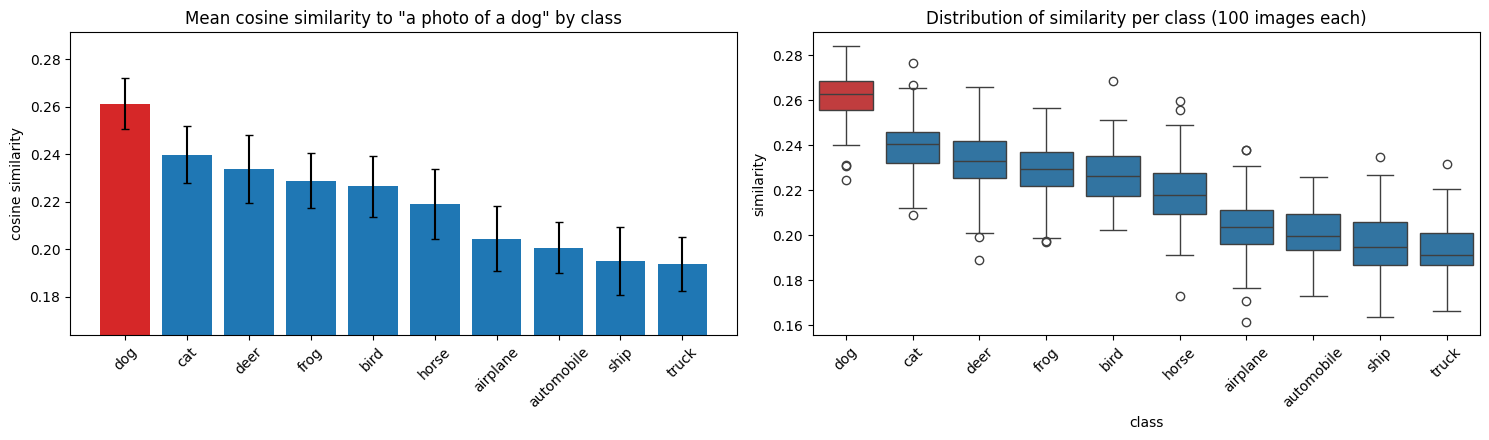

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = class_stats.index.tolist()
colors = ["#d62728" if c == TARGET_CLASS else "#1f77b4" for c in order]
axes[0].bar(order, class_stats["mean"], yerr=class_stats["std"], color=colors, capsize=3)
axes[0].set_ylim(class_stats["mean"].min() - 0.03, class_stats["mean"].max() + 0.03)
axes[0].set_title(f'Mean cosine similarity to "{CAPTION}" by class')
axes[0].set_ylabel("cosine similarity"); axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=dfA, x="class", y="similarity", order=order, ax=axes[1], palette=colors)
axes[1].set_title("Distribution of similarity per class (100 images each)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

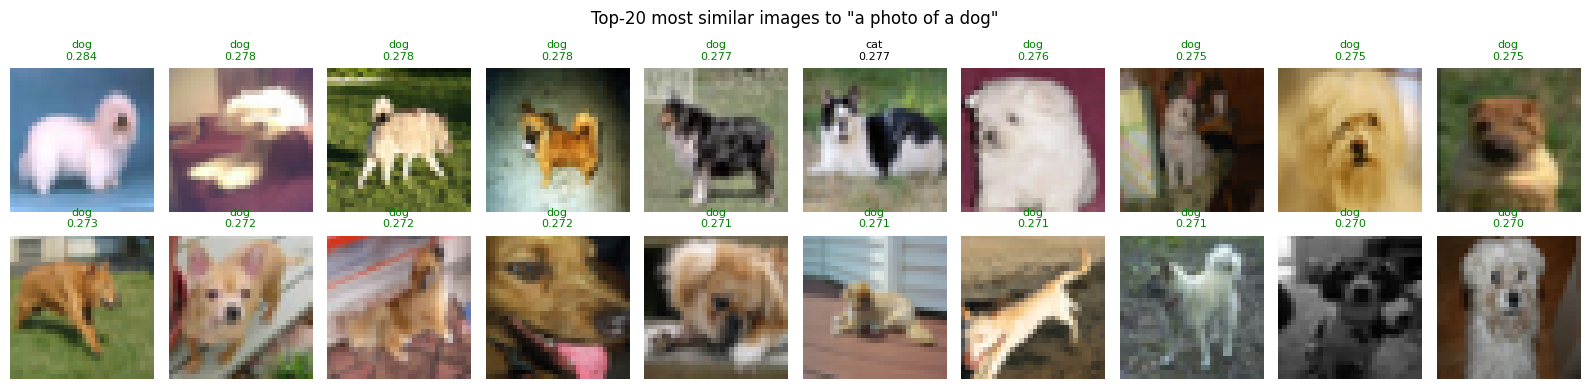

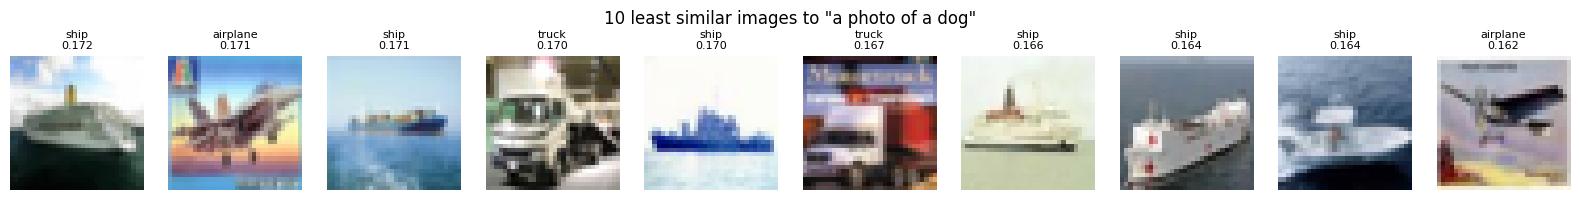

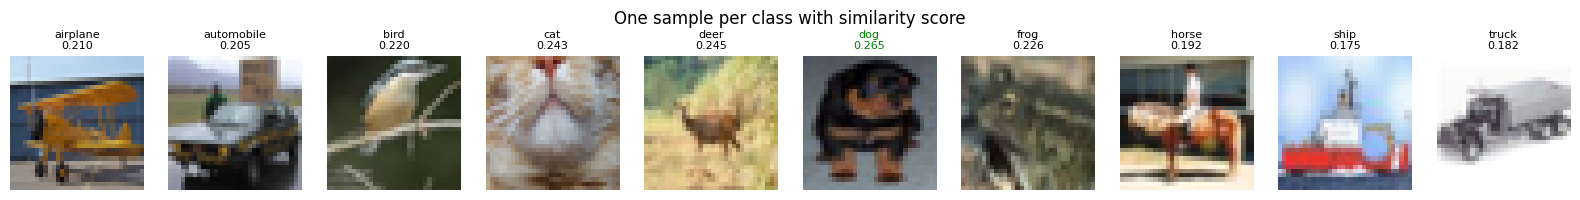

In [11]:
def show_grid(rows, title, ncols=10):
    n = len(rows); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.6, nrows * 2.0))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for ax, (_, r) in zip(np.atleast_1d(axes).ravel(), rows.iterrows()):
        img, _ = test_raw[int(r["idx"])]
        ax.imshow(img)
        ax.set_title(f'{r["class"]}\n{r["similarity"]:.3f}', fontsize=8,
                     color="green" if r["class"] == TARGET_CLASS else "black")
    fig.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

ranked = dfA.sort_values("similarity", ascending=False)
show_grid(ranked.head(20), f'Top-20 most similar images to "{CAPTION}"')
show_grid(ranked.tail(10), f'10 least similar images to "{CAPTION}"')
# one random example per class, with its score
show_grid(dfA.groupby("class", group_keys=False).sample(1, random_state=SEED), "One sample per class with similarity score")

In [12]:
# Retrieval quality: how many of the top-K images actually belong to the target class?
for K in [10, 50, 100]:
    p = (ranked.head(K)["class"] == TARGET_CLASS).mean()
    print(f"Precision@{K:<3} for '{TARGET_CLASS}': {p:.2f}")

Precision@10  for 'dog': 0.90
Precision@50  for 'dog': 0.88
Precision@100 for 'dog': 0.78


### Try a few more captions (optional but helpful for the write-up)

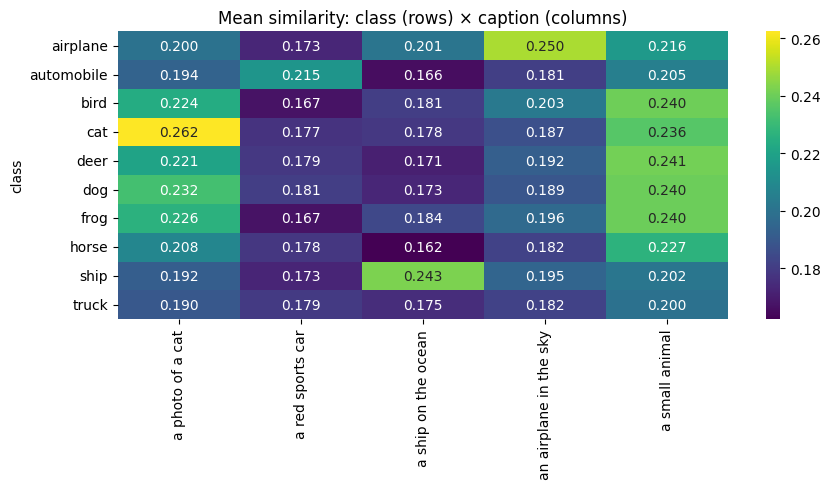

In [13]:
extra_captions = ["a photo of a cat", "a red sports car", "a ship on the ocean",
                  "an airplane in the sky", "a small animal"]
txt = encode_text(extra_captions).cpu()
S = (img_emb_A @ txt.T).numpy()
multi = pd.DataFrame(S, columns=extra_captions); multi["class"] = dfA["class"].values
plt.figure(figsize=(9, 5))
sns.heatmap(multi.groupby("class").mean().loc[CLASSES], annot=True, fmt=".3f", cmap="viridis")
plt.title("Mean similarity: class (rows) × caption (columns)"); plt.tight_layout(); plt.show()

### Findings — Part A (generated from your run)

In [14]:
top, second, bottom = class_stats.index[0], class_stats.index[1], class_stats.index[-1]
gap = class_stats.loc[top, "mean"] - class_stats.loc[second, "mean"]
print(f'Caption: "{CAPTION}"')
print(f"- Highest mean similarity: {top} ({class_stats.loc[top,'mean']:.4f}); "
      f"next: {second} ({class_stats.loc[second,'mean']:.4f}); gap = {gap:.4f}")
print(f"- Lowest mean similarity: {bottom} ({class_stats.loc[bottom,'mean']:.4f})")
print(f"- Range of raw cosine scores: {sims.min():.3f} to {sims.max():.3f}")
print(f"- Precision@100 for '{TARGET_CLASS}': {(ranked.head(100)['class']==TARGET_CLASS).mean():.2f}")

Caption: "a photo of a dog"
- Highest mean similarity: dog (0.2612); next: cat (0.2398); gap = 0.0215
- Lowest mean similarity: truck (0.1937)
- Range of raw cosine scores: 0.162 to 0.284
- Precision@100 for 'dog': 0.78


### Discussion — Part A
- **CLIP ranks the matching class first, but the margin is small.** For the caption *"a photo of a dog"*, dog images had the highest mean cosine similarity (0.2612), followed by cat (0.2398), a gap of only 0.0215. Truck was the lowest (0.1937).
- **Raw scores are bunched together.** All 1,000 similarities fall between 0.162 and 0.284. On their own, the absolute values mean little: the ranking and the relative gaps carry the information. That is why CLIP multiplies by a learned temperature (logit_scale ≈ 100) before the softmax.
- **The embedding space groups similar concepts.** The closest non-dog class is cat, another small four-legged pet. Vehicles such as truck sit at the far end.
- **Retrieval is strong at the top and weaker further down.** Precision@10 = 0.90 and Precision@50 = 0.88, but Precision@100 = 0.78. About 22 of the top 100 images are not dogs (mostly other animals). Many low-resolution 32×32 dog images rank below clearer cats.
- **Caption wording matters.** In the multi-caption heatmap, each specific caption lights up its own class. This motivates the prompt ensembling used in Part B.

---
# Part B — Zero-shot classification on CIFAR-10

We build one text embedding per class from an **ensemble of prompt templates**, averaged and re-normalized. Each test image is assigned the class whose text embedding has the highest cosine similarity. No CIFAR-10 training is used.

In [15]:
TEMPLATES = [
    "a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.",
    "a photo of the small {}.", "a pixelated photo of the {}.", "a close-up photo of a {}.",
    "a bright photo of a {}.", "a cropped photo of the {}.", "a good photo of the {}.",
    "a photo of the big {}.",
]
# slightly more natural names help CLIP
NAMES = {"automobile": "car"}

@torch.no_grad()
def build_classifier(templates):
    W = []
    for c in CLASSES:
        e = encode_text([t.format(NAMES.get(c, c)) for t in templates])
        W.append(F.normalize(e.mean(0), dim=-1))
    return torch.stack(W)          # (10, 512)

W_single   = build_classifier(["a photo of a {}."]).cpu()
W_ensemble = build_classifier(TEMPLATES).cpu()

In [16]:
# Encode the full 10,000-image test set (about 1–2 minutes on a T4)
loader_B = DataLoader(test_clip, batch_size=256, shuffle=False, num_workers=2)
img_emb_B, y_true = encode_images(loader_B)
y_true = y_true.numpy()

logit_scale = model.logit_scale.exp().item()
def predict(W):
    logits = logit_scale * img_emb_B @ W.T
    return logits.softmax(-1).numpy(), logits.argmax(-1).numpy()

_, pred_single = predict(W_single)
probs, y_pred  = predict(W_ensemble)
print(f"Overall accuracy, single prompt 'a photo of a {{}}.': {accuracy_score(y_true, pred_single):.4f}")
print(f"Overall accuracy, {len(TEMPLATES)}-template ensemble: {accuracy_score(y_true, y_pred):.4f}")

Overall accuracy, single prompt 'a photo of a {}.': 0.8822
Overall accuracy, 10-template ensemble: 0.8927


### Per-class accuracy

,class,n_test,correct,accuracy,acc_single_prompt
0,horse,1000,976,97.60%,97.10%
1,truck,1000,974,97.40%,97.20%
2,ship,1000,966,96.60%,96.00%
3,airplane,1000,906,90.60%,88.90%
4,automobile,1000,889,88.90%,90.20%
5,dog,1000,888,88.80%,89.10%
6,bird,1000,876,87.60%,89.70%
7,cat,1000,860,86.00%,85.60%
8,deer,1000,808,80.80%,76.90%
9,frog,1000,784,78.40%,71.50%


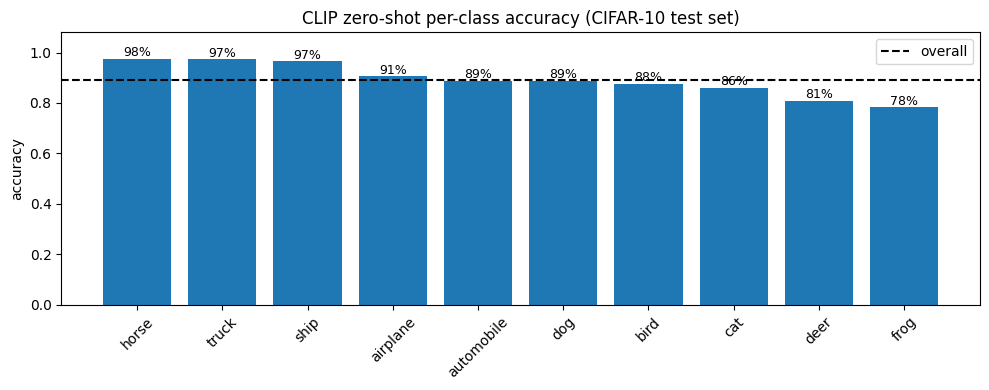

              precision    recall  f1-score   support

    airplane      0.953     0.906     0.929      1000
  automobile      0.968     0.889     0.927      1000
        bird      0.855     0.876     0.866      1000
         cat      0.821     0.860     0.840      1000
        deer      0.904     0.808     0.853      1000
         dog      0.847     0.888     0.867      1000
        frog      0.970     0.784     0.867      1000
       horse      0.830     0.976     0.897      1000
        ship      0.931     0.966     0.948      1000
       truck      0.889     0.974     0.930      1000

    accuracy                          0.893     10000
   macro avg      0.897     0.893     0.892     10000
weighted avg      0.897     0.893     0.892     10000



In [17]:
cm = confusion_matrix(y_true, y_pred, labels=range(10))
per_class = pd.DataFrame({
    "class": CLASSES,
    "n_test": cm.sum(1),
    "correct": np.diag(cm),
    "accuracy": np.diag(cm) / cm.sum(1),
    "acc_single_prompt": [np.mean(pred_single[y_true == c] == c) for c in range(10)],
}).sort_values("accuracy", ascending=False).reset_index(drop=True)
display(per_class.style.format({"accuracy": "{:.2%}", "acc_single_prompt": "{:.2%}"}))

plt.figure(figsize=(10, 4))
plt.bar(per_class["class"], per_class["accuracy"], color="#1f77b4")
plt.axhline(accuracy_score(y_true, y_pred), ls="--", c="k", label="overall")
for i, a in enumerate(per_class["accuracy"]): plt.text(i, a + 0.01, f"{a:.0%}", ha="center", fontsize=9)
plt.ylim(0, 1.08); plt.ylabel("accuracy"); plt.title("CLIP zero-shot per-class accuracy (CIFAR-10 test set)")
plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

### Confusion matrix

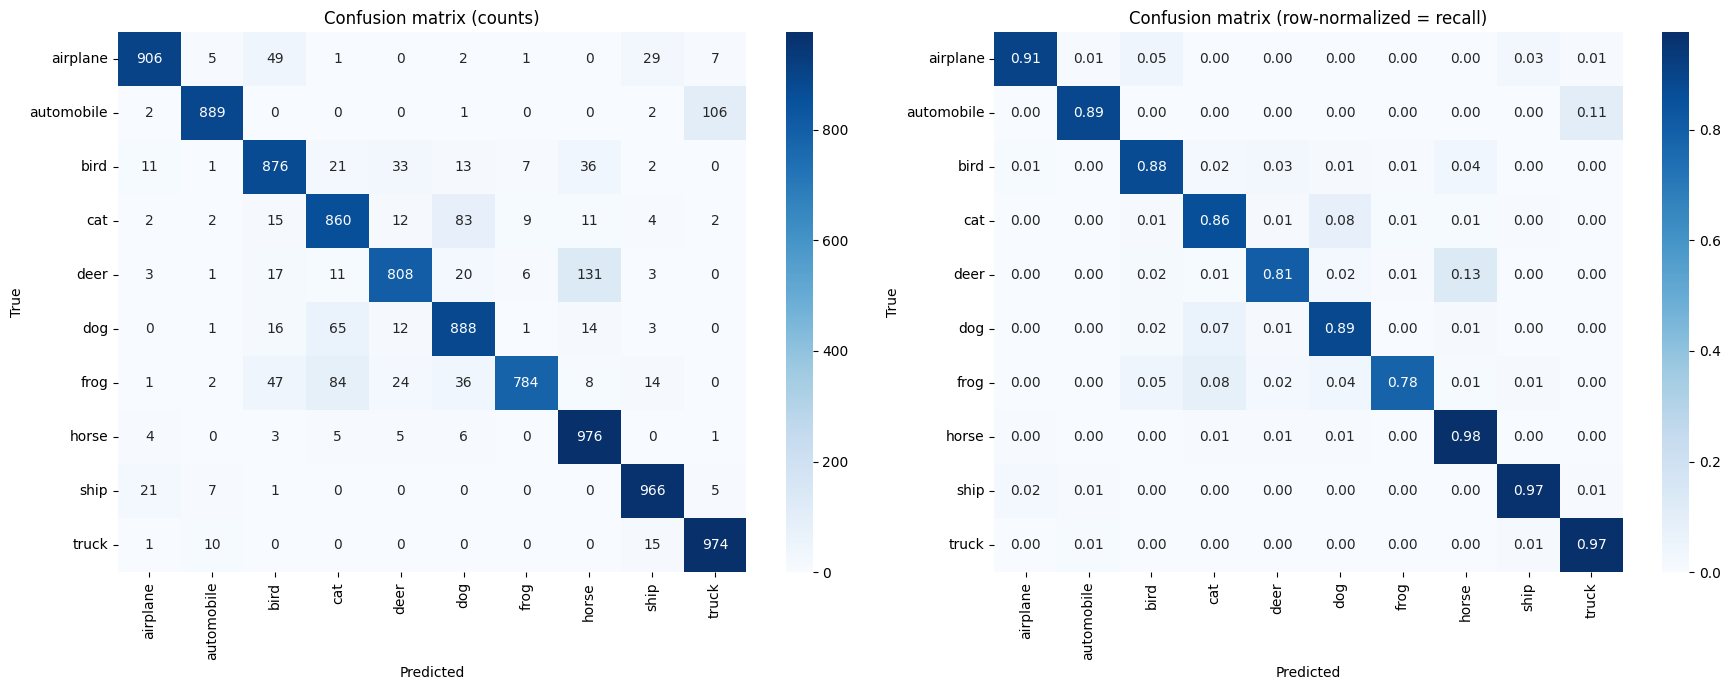

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
cm_norm = cm / cm.sum(1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalized = recall)")
for ax in axes: ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

In [19]:
# Most frequent confusions (off-diagonal)
off = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(10) for j in range(10) if i != j]
top_conf = pd.DataFrame(sorted(off, key=lambda t: -t[2])[:8], columns=["true", "predicted", "count"])
top_conf

,true,predicted,count
0,deer,horse,131
1,automobile,truck,106
2,frog,cat,84
3,cat,dog,83
4,dog,cat,65
5,airplane,bird,49
6,frog,bird,47
7,bird,horse,36


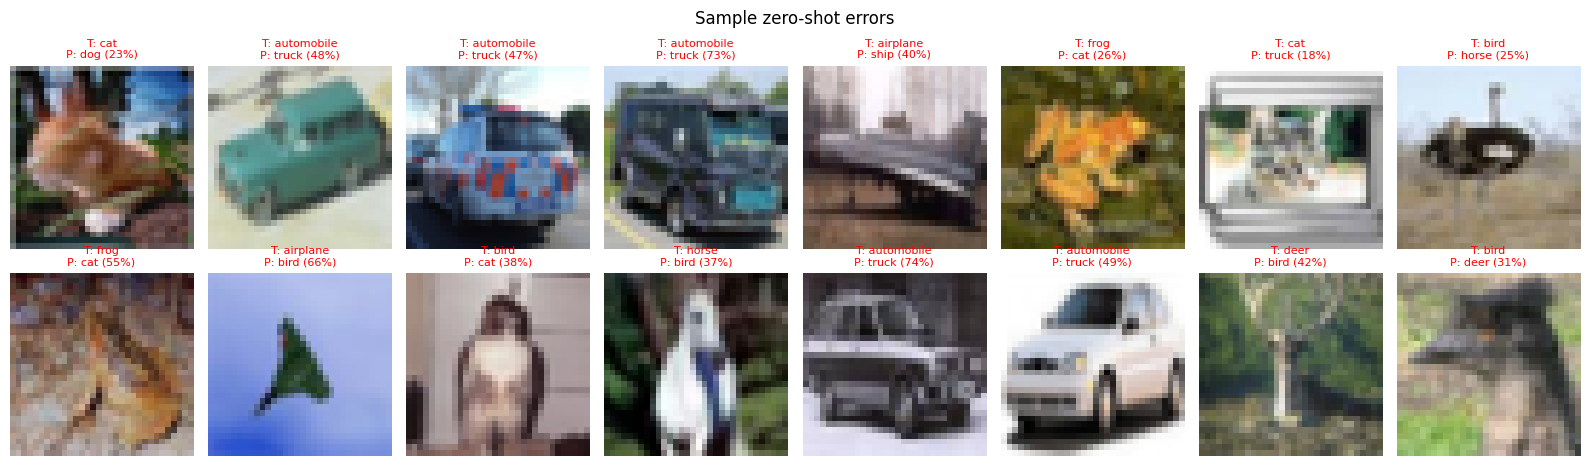

In [20]:
# Example misclassifications, with CLIP's confidence
wrong = np.where(y_pred != y_true)[0]
pick = np.random.default_rng(SEED).choice(wrong, 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(test_raw[i][0]); ax.axis("off")
    ax.set_title(f"T: {CLASSES[y_true[i]]}\nP: {CLASSES[y_pred[i]]} ({probs[i].max():.0%})", fontsize=8, color="red")
fig.suptitle("Sample zero-shot errors"); plt.tight_layout(); plt.show()

### Findings — Part B (generated from your run)

In [21]:
acc = accuracy_score(y_true, y_pred)
best, worst = per_class.iloc[0], per_class.iloc[-1]
print(f"- Overall zero-shot accuracy: {acc:.2%} (single prompt: {accuracy_score(y_true, pred_single):.2%}; "
      f"ensemble gain: {(acc-accuracy_score(y_true, pred_single))*100:+.2f} pts)")
print(f"- Best class: {best['class']} ({best['accuracy']:.2%}); worst class: {worst['class']} ({worst['accuracy']:.2%})")
r = top_conf.iloc[0]
print(f"- Most common confusion: {r['true']} -> {r['predicted']} ({r['count']} images)")
print(f"- Chance level for 10 classes: 10%. CLIP gets {acc/0.10:.1f}x chance with zero training examples.")

- Overall zero-shot accuracy: 89.27% (single prompt: 88.22%; ensemble gain: +1.05 pts)
- Best class: horse (97.60%); worst class: frog (78.40%)
- Most common confusion: deer -> horse (131 images)
- Chance level for 10 classes: 10%. CLIP gets 8.9x chance with zero training examples.


### Discussion — Part B
- **Strong zero-shot performance.** CLIP ViT-B/32 classified the 10,000 CIFAR-10 test images with **89.27% accuracy**. It was never trained on CIFAR-10 labels, and the result is 8.9× the 10% chance level.
- **Prompt ensembling helps a little.** Averaging 10 prompt templates raised accuracy from 88.22% (single prompt "a photo of a {}.") to 89.27%, a gain of 1.05 points.
- **Per-class results vary widely.** The best class was **horse (97.60%)** and the worst was **frog (78.40%)**, a spread of almost 20 points. This is despite every class having the same 1,000 test images.
- **Errors are semantic, not random.** The most common confusion was **deer → horse (131 images)**: 13.1% of all deer were labeled horse. Both are brown four-legged animals usually photographed on grass, and at 32×32 the antlers and body shape that separate them are mostly lost. It also helps explain horse's very high accuracy: CLIP leans toward "horse" for ambiguous hoofed animals.
- **Link to Part A.** Zero-shot classification is the Part A similarity computation run against 10 class captions, followed by an argmax. The classes that sat close together in Part A (dog/cat; animals versus vehicles) are where the confusion matrix shows errors.
- **Limitations and next steps:** low input resolution (upscaled from 32×32); sensitivity to prompt wording; class bias toward horse. Possible improvements: a larger backbone (ViT-L/14), class-specific prompts (e.g. "a photo of a deer with antlers"), or a linear probe / few-shot fine-tuning.

---
## Summary
| | Result |
|---|---|
| Model | `openai/clip-vit-base-patch32` (zero-shot, no fine-tuning) |
| **Part A** — caption vs. images | Caption *"a photo of a dog"* compared with 1,000 CIFAR-10 test images (100 per class) |
| Highest / lowest mean similarity | dog **0.2612** (next: cat 0.2398) / truck **0.1937** |
| Cosine similarity range | 0.162 – 0.284 |
| Retrieval precision (dog) | P@10 = **0.90**, P@50 = **0.88**, P@100 = **0.78** |
| **Part B** — zero-shot classification | All 10,000 CIFAR-10 test images |
| Overall accuracy | **89.27%** with a 10-prompt ensemble (88.22% with a single prompt, +1.05 pts) |
| Best / worst class | horse **97.60%** / frog **78.40%** |
| Most common confusion | deer → horse (131 images) |

**Takeaway:** CLIP's shared image–text embedding space ranks and classifies images it was never trained on with high accuracy. Its errors cluster among visually and semantically similar classes, such as deer/horse and dog/cat, and the 32×32 resolution of CIFAR-10 makes them harder to separate.